# Industrial Machine Failure Detection â€” Kaggle AI4I 2020
**Case study:** classify whether a machine is in a failure state from product type and operating measurements.

Kaggle: https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020
Original dataset: S. Matzka (2020), AI4I 2020 Predictive Maintenance Dataset, UCI, DOI 10.24432/C5HS5C, CC BY 4.0.

This is a synthetic industrial dataset with 10,000 rows. It is less elementary than Iris: mixed numeric/categorical inputs, rare failures, domain features and a decision threshold.
It detects a labeled failure state, **not** time until a future failure. No prediction horizon or machine history is available.

Run this notebook in **Jupyter Notebook**. Training code lives only in these cells; the FastAPI application only performs inference.
Download the actual Kaggle CSV first with `python scripts/download_data.py`. There is no generated-data fallback.

## 1. Load and verify the Kaggle data
Install requirements-dev.txt in a Python 3.12 environment before starting Jupyter. Run from the project root or notebooks folder.
The downloader verifies the expected schema and records the CSV checksum. We verify the hash again before training.
The feature allowlist excludes identifiers and every failure label: Target/Machine failure, Failure Type and TWF/HDF/PWF/OSF/RNF.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import sklearn, joblib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
    accuracy_score, precision_score, recall_score, fbeta_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay)
from app.features import FEATURES, NUMERIC, validate_dataset, engineer_features

csv = ROOT / "data/predictive_maintenance.csv"
provenance_path = ROOT / "data/provenance.json"
if not csv.exists() or not provenance_path.exists():
    raise FileNotFoundError("Actual Kaggle data required. Run python scripts/download_data.py first.")
provenance = json.loads(provenance_path.read_text())
assert provenance["dataset_slug"] == "stephanmatzka/predictive-maintenance-dataset-ai4i-2020"
assert provenance["assignment_dataset"] is True
assert provenance["sha256"] == hashlib.sha256(csv.read_bytes()).hexdigest(), "Dataset hash mismatch"
df = pd.read_csv(csv)
assert len(df) == 10000
X, y = validate_dataset(df)
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
print(json.dumps(provenance, indent=2))
display(df.head())
print("Class counts:", y.value_counts().to_dict(), "Failure prevalence:", y.mean())
display(X.describe(include="all"))

{
  "source": "Kaggle",
  "dataset_slug": "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
  "page": "https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
  "download_url": "https://www.kaggle.com/api/v1/datasets/download/stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
  "archive_member": "ai4i2020.csv",
  "download_method": "Kaggle download API",
  "sha256": "dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e",
  "rows": 10000,
  "assignment_dataset": true
}


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Class counts: {0: 9661, 1: 339} Failure prevalence: 0.0339


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,3,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN
freq,6000,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000
std,NaN,2.000259,1.483734,179.284096,9.968934,63.654147
min,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000


## 2. Hold out the final test set
A stratified 80/20 random split preserves rare-failure proportions. This is a record-level classification benchmark. Random splitting of sequential synthetic records may be optimistic; it does not establish future-time or unseen-machine performance. Such deployment would need chronological or machine-group holdouts.

The test set remains untouched until the decision threshold is fixed. Three-fold training-only out-of-fold predictions select a threshold by F2 (recall receives more weight than precision). No scaling is needed for trees.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training:", X_train.shape, "Test:", X_test.shape)

model = Pipeline([
    ("features", FunctionTransformer(engineer_features, validate=False)),
    ("preprocess", ColumnTransformer([
        ("type", OneHotEncoder(handle_unknown="error", sparse_output=False), ["Type"]),
        ("numeric", "passthrough", NUMERIC)
    ], remainder="drop")),
    ("classifier", RandomForestClassifier(
        n_estimators=200, max_depth=14, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
oof_probability = cross_val_predict(
    model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
p, r, thresholds = precision_recall_curve(y_train, oof_probability)
f2_values = 5 * p[:-1] * r[:-1] / np.maximum(4 * p[:-1] + r[:-1], 1e-12)
threshold = float(thresholds[np.argmax(f2_values)])
print("Training-only out-of-fold average precision:", average_precision_score(y_train, oof_probability))
print("Selected threshold:", threshold, "OOF F2:", float(f2_values.max()))
model.fit(X_train, y_train)
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)

Training: (8000, 6) Test: (2000, 6)


Training-only out-of-fold average precision: 0.8914088015550561
Selected threshold: 0.3706400597335668 OOF F2: 0.8544776119402986


## 3. Evaluate once on the held-out test partition
An all-healthy classifier can appear accurate because most machines are healthy. Report PR-AUC as **average precision**, ROC-AUC, precision, recall, F2 and the confusion matrix, rather than accuracy alone. F2 is used here as an educational recall preference; real alert thresholds require measured failure and inspection costs.

Random-forest probabilities are uncalibrated model scores. They are not certified failure-risk estimates.

{
  "average_precision": 0.8803783923353562,
  "roc_auc": 0.9788507794422117,
  "precision": 0.890625,
  "recall": 0.8382352941176471,
  "f2": 0.8482142857142857,
  "accuracy": 0.991,
  "baseline_average_precision": 0.034,
  "test_failure_prevalence": 0.034
}
              precision    recall  f1-score   support

     Healthy       0.99      1.00      1.00      1932
     Failure       0.89      0.84      0.86        68

    accuracy                           0.99      2000
   macro avg       0.94      0.92      0.93      2000
weighted avg       0.99      0.99      0.99      2000



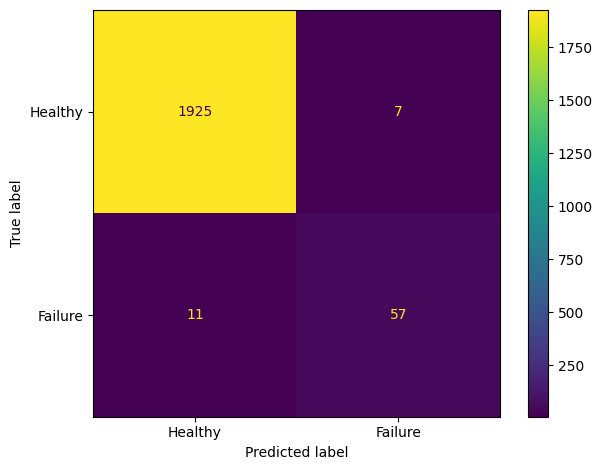

In [3]:
probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
predictions = (probability >= threshold).astype(int)
baseline_probability = baseline.predict_proba(X_test)[:, list(baseline.classes_).index(1)]
metrics = {
    "average_precision": float(average_precision_score(y_test, probability)),
    "roc_auc": float(roc_auc_score(y_test, probability)),
    "precision": float(precision_score(y_test, predictions, zero_division=0)),
    "recall": float(recall_score(y_test, predictions, zero_division=0)),
    "f2": float(fbeta_score(y_test, predictions, beta=2, zero_division=0)),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "baseline_average_precision": float(average_precision_score(y_test, baseline_probability)),
    "test_failure_prevalence": float(y_test.mean())
}
print(json.dumps(metrics, indent=2))
report = classification_report(y_test, predictions, output_dict=True, zero_division=0)
print(classification_report(y_test, predictions, target_names=["Healthy", "Failure"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, predictions, labels=[0, 1]),
                       display_labels=["Healthy", "Failure"]).plot()
plt.tight_layout()
plt.savefig(ARTIFACTS / "confusion_matrix.png", dpi=150)
plt.show()
plt.close()
# Broad gates only: CI should catch a broken model, not chase a lucky score.
assert metrics["average_precision"] > metrics["baseline_average_precision"]
assert metrics["roc_auc"] >= 0.80
assert metrics["recall"] >= 0.40

## 4. Save model.joblib and its parameters
The artifact contains feature engineering, categorical encoding and the fitted forest. The threshold is saved separately in metadata.json and is applied by the API.
Feature engineering is imported from app.features so the serialized pipeline loads in Docker without notebook-only class definitions.
Only trusted joblib files should be loaded.

In [4]:
metadata = {
    "model_version": "maintenance-rf-v1",
    "features": FEATURES, "classes": [0, 1],
    "train_rows": len(X_train), "test_rows": len(X_test),
    "random_state": 42, "decision_threshold": threshold,
    "threshold_selection": "Max F2 on training-only 3-fold out-of-fold predictions",
    "training_oof_average_precision": float(average_precision_score(y_train, oof_probability)),
    "metrics": metrics,
    "dataset": provenance,
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "limitations": [
        "Synthetic data; record-level random split may be optimistic.",
        "Current-state classification, not future-failure forecasting.",
        "Uncalibrated probabilities; no machine-specific history.",
        "No automatic production drift detection or retraining."
    ]
}
parameters = {
    "classifier_hyperparameters": model.named_steps["classifier"].get_params(),
    "encoded_feature_names": model.named_steps["preprocess"].get_feature_names_out().tolist(),
    "feature_importances": model.named_steps["classifier"].feature_importances_.tolist(),
    "decision_threshold": threshold
}
joblib.dump(model, ARTIFACTS / "model.joblib")
for name, value in [("metadata.json", metadata), ("parameters.json", parameters),
                    ("classification_report.json", report)]:
    (ARTIFACTS / name).write_text(json.dumps(value, indent=2))
reloaded = joblib.load(ARTIFACTS / "model.joblib")
assert np.allclose(reloaded.predict_proba(X_test), model.predict_proba(X_test))
print("Saved and verified complete model.joblib")
display(pd.DataFrame({
    "feature": parameters["encoded_feature_names"],
    "importance": parameters["feature_importances"]
}).sort_values("importance", ascending=False))

Saved and verified complete model.joblib


,feature,importance
6,numeric__Torque [Nm],0.189755
9,numeric__Power [W],0.187904
5,numeric__Rotational speed [rpm],0.185617
7,numeric__Tool wear [min],0.136305
10,numeric__Wear torque [minNm],0.118938
8,numeric__Temperature difference [K],0.094007
3,numeric__Air temperature [K],0.048465
4,numeric__Process temperature [K],0.027954
1,type__Type_L,0.004534
2,type__Type_M,0.004385


## 5. Deployment demo
Open app/main.py in VS Code. Start the API with `python -m uvicorn app.main:app --host 127.0.0.1 --port 8000`.
Try /predict at http://localhost:8000/docs:

```json
{"product_type":"M","air_temperature_k":298.1,"process_temperature_k":308.6,
 "rotational_speed_rpm":1551,"torque_nm":42.8,"tool_wear_min":0}
```

Stop local Uvicorn, then use `docker compose up --build -d` and `python scripts/smoke_test.py` to test real container endpoints.
See README.md for repository creation and GitHub Actions verification.
The notebook must actually complete before a saved model or successful training is claimed.